# 02 Basaltic glass (EPMA, session 20/12/2016)

Same steps as `01_olivine`, with VG-2 as the only standard (step 3). There is no Fo/Fa file for the glass, so step 7 does not apply.

In [1]:
# --- config ---
from pathlib import Path
import sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="Unknown extension")      # harmless openpyxl warning on Standards.xlsx
sys.path.insert(0, "src")
from geohelpers import read_jeol, read_dl, read_cal, read_ref, mean_2sd

DATA, OUT, FIG = Path("data"), Path("outputs"), Path("figures/glass")
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
STD = "VG-2"                                       # the only standard used for the correction (step 3)
REF_ROWS = {"Std VGA99": "VGA99", "Std VG2": "VG-2", "Std Scapolite": "Scap", "Std KE3": "KE3"}   # xlsx row: session name
OX = ["SiO2", "TiO2", "Al2O3", "FeO", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5", "SO3", "Cl", "F"]
TRAIN, TEST = [3, 4, 57, 100], [56, 101]           # VG-2 analyses that compute / test the CF in step 6
pd.set_option("display.width", 200, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9})

## Steps 1 and 2. One table

There is no ratios file for the glass, so step 1 is the `_oxide` file alone; Comment first, then the oxides. The last number in a Comment is the spot (9 per sample). `UnknA-Flow1-1` was measured twice under the same name (No. 71 to 79 and 89 to 97): the second run is kept as a separate set, `UnknA-Flow1-1 (run 2)`, and compared with the first before anything is averaged.

In [2]:
gl = read_jeol(DATA / "bgls_20122016_oxide.txt")
gl["Sample"] = gl.Comment.str.rstrip("_").str.rsplit("_", n=1).str[0]
gl.loc[gl.Sample.eq("UnknA-Flow1-1") & gl["No."].between(89, 97), "Sample"] = "UnknA-Flow1-1 (run 2)"
gl = gl[["No.", "Comment", "Sample"] + OX + ["Total"]]
is_std = gl.Sample.isin(REF_ROWS.values())                          # all four standards leave the sample set

print(gl[is_std].groupby("Sample")["No."].apply(list).to_string())
print(gl[~is_std].groupby("Sample").size().to_string())

Sample
KE3      [5, 6, 58, 59, 102, 103]
Scap     [7, 8, 60, 61, 104, 105]
VG-2     [3, 4, 56, 57, 100, 101]
VGA99      [1, 2, 54, 55, 98, 99]
Sample
1982-CS2-L3A             9
1982-CS2-L5B             9
UnknA-BatokeCS1-3        9
UnknA-C21                9
UnknA-C22-PS1-L2         9
UnknA-C22-PS1-L3         9
UnknA-Flow1-1            9
UnknA-Flow1-1 (run 2)    9
UnknA-Flow1-2            9


## Step 3. Plot the standard and remove obvious outliers by eye

**Only VG-2 is used.** The session also measured VGA99, Scapolite and KE3; using VG-2 alone is our choice and is reported as such. The one requirement is that the standard has a reference value for every oxide to be corrected: VG-2 is the only standard measured in this session with reference values for all 13 in `Standards.xlsx` (table below), and it is a basaltic glass like the samples. VGA99, Scapolite and KE3 are not used anywhere below. The instrument itself was calibrated on VGA99, Scapolite, KE3 and rhodonite (`_std-cnd`, printed below); the correction here is applied on top of that calibration.

**Reference values:** `Standards.xlsx`, row *Std VG2*, with S converted to SO₃ (× 2.4972). VG-2 is not one of the calibration standards in `bgls_20122016_std-cnd.txt`, so that file has no higher-precision values for it.

Each oxide of VG-2 is plotted against analysis number, with the reference value. A point is removed only when it is clearly separated from the other five and pulls the mean.

**Removed** (decided from the plots below), all from analysis No. 100:
- SiO₂: 50.39 wt% against 51.17 to 51.66 for the other analyses.
- Al₂O₃: 13.55 wt% against 13.96 to 14.07.
- Cl: 0.022 wt% against 0.030 to 0.035.

No. 100 also has the lowest total of the six (100.0 against 101.0 to 101.7 wt%), while No. 101, measured right after it, is normal in all three oxides: one poor analysis, not a change of the instrument. Its other oxides are kept.

**Kept:** MnO (0.15 to 0.26 wt%), P₂O₅ (0.16 to 0.22) and F (0.010 to 0.097) scatter widely with no single point standing out. They are only a few times their detection limit, and F is below it in three of the six analyses (step 5).

oxides with a reference value (of 13): {'VGA99': 12, 'VG-2': 13, 'Scap': 9, 'KE3': 3}
        SiO2  TiO2  Al2O3    FeO   MnO   MgO    CaO  Na2O   K2O  P2O5     SO3      Cl      F
VGA99  50.94  4.06  12.49  13.30  0.15  5.08   9.30  2.66  0.82  0.38  0.0425  0.0271    NaN
VG-2   50.81  1.85  14.06  11.84  0.22  6.71  11.12  2.62  0.19  0.20  0.3571  0.0329  0.032
Scap   49.78   NaN  25.05   0.17   NaN   NaN  13.58  5.20  0.94   NaN  1.3235  1.4300  0.016
KE3      NaN   NaN    NaN    NaN   NaN   NaN    NaN   NaN   NaN   NaN  0.0300  0.3900  0.470

instrument calibration (_std-cnd): {'KE3': ['F'], 'Rhodonite': ['MnO'], 'Scapolite_bgls': ['SO3', 'Cl'], 'VGA99-15KV': ['Na2O', 'FeO', 'SiO2', 'K2O', 'Al2O3', 'P2O5', 'MgO', 'CaO', 'TiO2']}


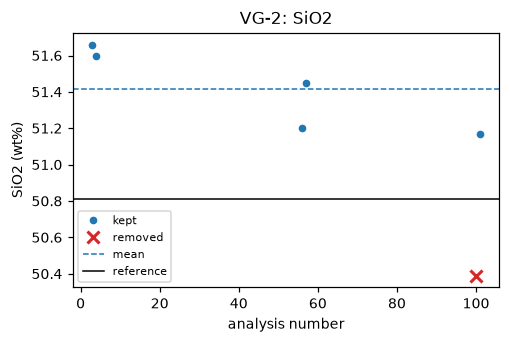

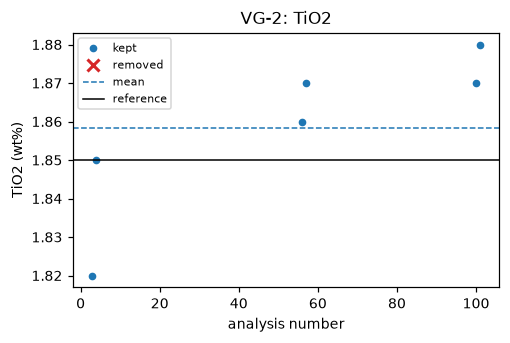

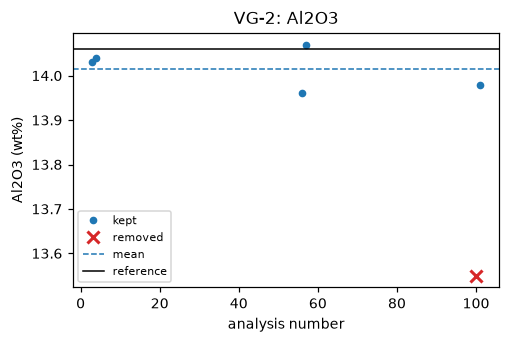

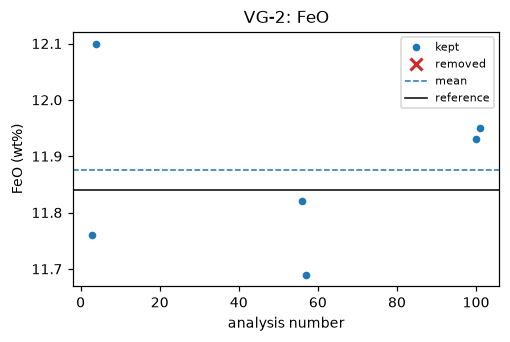

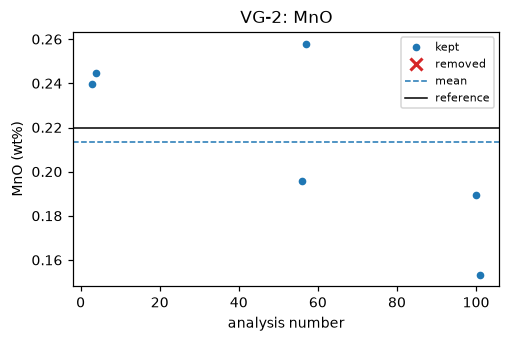

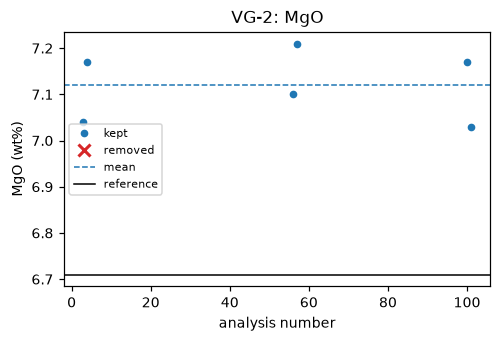

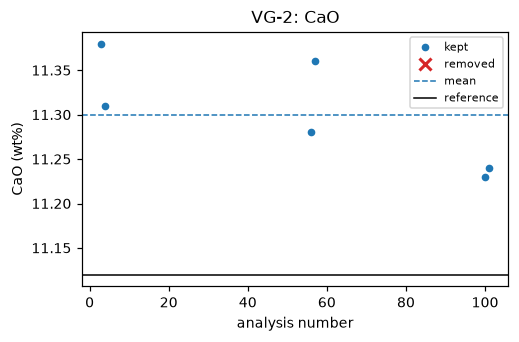

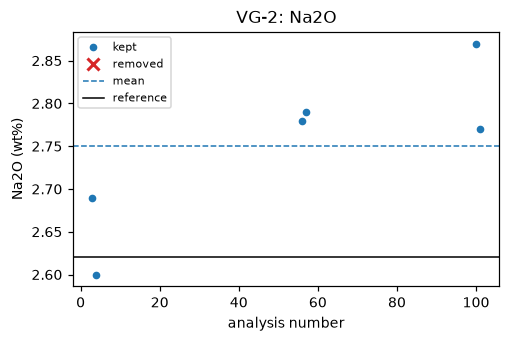

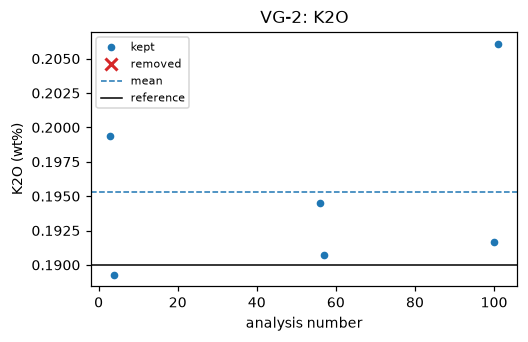

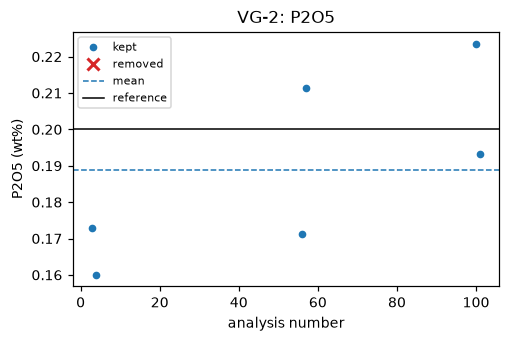

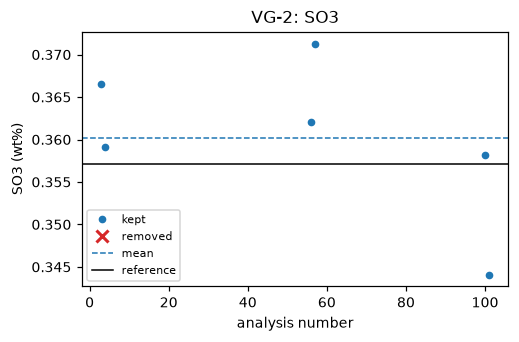

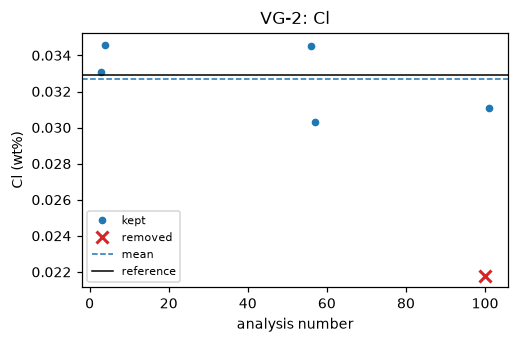

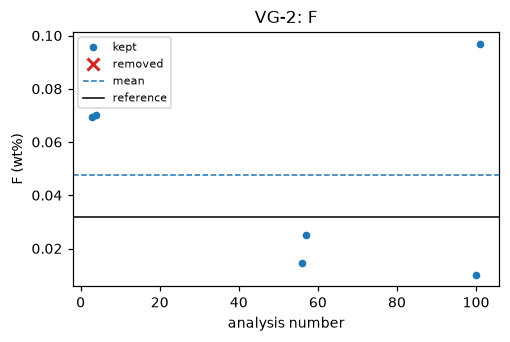

In [3]:
ref = read_ref(DATA / "Standards.xlsx", REF_ROWS)[OX]
print(f"oxides with a reference value (of {len(OX)}):", ref.notna().sum(axis=1).to_dict())
print(ref.round(4).to_string())
cal = read_cal(DATA / "bgls_20122016_std-cnd.txt")
print("\ninstrument calibration (_std-cnd):", cal.groupby("standard").oxide.apply(list).to_dict())
GT = ref.loc[STD].astype(float)

std = gl[gl.Sample.eq(STD)].set_index("No.")
DROP = {"SiO2": [100], "Al2O3": [100], "Cl": [100]}
clean = std[OX].copy()
for el, nos in DROP.items():
    clean.loc[nos, el] = np.nan

def plot_std(el, fname=None):
    fig, ax = plt.subplots(figsize=(5, 3))
    keep = clean[el].notna()
    ax.plot(std.index[keep], std.loc[keep, el], "o", ms=4, label="kept")
    ax.plot(std.index[~keep], std.loc[~keep, el], "x", ms=8, mew=2, color="C3", label="removed")
    ax.axhline(clean[el].mean(), ls="--", lw=1, color="C0", label="mean")
    ax.axhline(GT[el], color="k", lw=1, label="reference")
    ax.set(xlabel="analysis number", ylabel=f"{el} (wt%)", title=f"{STD}: {el}")
    ax.legend(fontsize=7)
    if fname: fig.savefig(fname)
    plt.show()

for el in OX:
    plot_std(el, FIG / f"std_{el}.png")

## Step 4. Mean, SD and correction factor; correct every analysis

CF = mean / reference, from the VG-2 analyses kept in step 3. Every analysis, samples and standards, is divided by the CF of its oxide; the total is recomputed as the sum of the corrected oxides. `SD_all` is the SD before the removals, to show their effect.

In [4]:
cf = pd.DataFrame({"n": clean.count(), "mean": clean.mean(), "SD": clean.std(), "SD_all": std[OX].std(),
                   "reference": GT})
cf["CF"] = cf["mean"] / cf["reference"]
print(cf.round(4).to_string())

corr = gl.copy()
corr[OX] = gl[OX] / cf["CF"]
corr["Total"] = corr[OX].sum(axis=1)

with pd.ExcelWriter(OUT / "glass_step4_standards.xlsx") as xw:
    std.reset_index().to_excel(xw, sheet_name="VG-2 raw", index=False)
    cf.to_excel(xw, sheet_name="correction factors")
    gl.to_excel(xw, sheet_name="all raw", index=False)
    corr.to_excel(xw, sheet_name="all corrected", index=False)

       n     mean      SD  SD_all  reference      CF
SiO2   5  51.4160  0.2246  0.4645    50.8100  1.0119
TiO2   6   1.8583  0.0214  0.0214     1.8500  1.0045
Al2O3  5  14.0160  0.0451  0.1945    14.0600  0.9969
FeO    6  11.8750  0.1482  0.1482    11.8400  1.0030
MnO    6   0.2135  0.0404  0.0404     0.2200  0.9705
MgO    6   7.1200  0.0748  0.0748     6.7100  1.0611
CaO    6  11.3000  0.0616  0.0616    11.1200  1.0162
Na2O   6   2.7500  0.0932  0.0932     2.6200  1.0496
K2O    6   0.1953  0.0064  0.0064     0.1900  1.0278
P2O5   6   0.1888  0.0250  0.0250     0.2000  0.9438
SO3    6   0.3602  0.0093  0.0093     0.3571  1.0088
Cl     5   0.0327  0.0020  0.0048     0.0329  0.9942
F      6   0.0477  0.0358  0.0358     0.0320  1.4911


## Step 5. Flag correction factors outside ±5 %

A CF more than 5 % from 1 means VG-2 was measured more than 5 % away from its reference value for that oxide; those oxides are reported. The detection limit is shown next to them (median of the six VG-2 analyses, from `_all`), because a standard close to its detection limit gives a poorly defined CF.

        mean  reference      CF  DL_VG2  mean_over_DL
MgO   7.1200      6.710  1.0611  0.0298      238.5308
P2O5  0.1888      0.200  0.9438  0.0341        5.5289
F     0.0477      0.032  1.4911  0.0354        1.3498

F below its detection limit in 3 of 6 VG-2 analyses


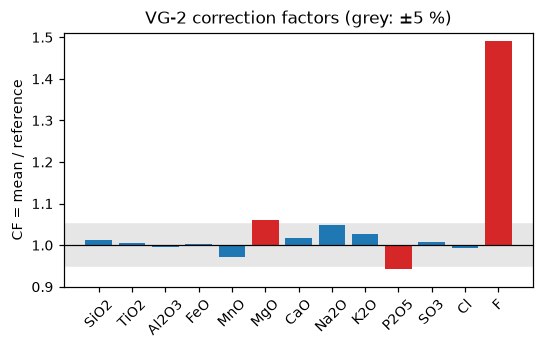

In [5]:
dl = read_dl(DATA / "bgls_20122016_all.txt")[OX]                  # detection limit of every analysis, wt% oxide
cf["flag"] = (cf.CF - 1).abs() > 0.05
cf["DL_VG2"] = dl.loc[std.index].median()
cf["mean_over_DL"] = cf["mean"] / cf.DL_VG2
print(cf.loc[cf.flag, ["mean", "reference", "CF", "DL_VG2", "mean_over_DL"]].round(4).to_string())
print(f"\nF below its detection limit in {int((std.F < dl.loc[std.index, 'F']).sum())} of {len(std)} VG-2 analyses")

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(cf.index, cf.CF - 1, bottom=1, color=np.where(cf.flag, "C3", "C0"))
ax.set_ylim(min(0.9, cf.CF.min() - 0.02), max(1.1, cf.CF.max() + 0.02))
ax.axhspan(0.95, 1.05, color="0.9", zorder=0); ax.axhline(1, color="k", lw=0.8)
ax.set(ylabel="CF = mean / reference", title=f"{STD} correction factors (grey: ±5 %)")
ax.tick_params(axis="x", rotation=45)
fig.savefig(FIG / "cf.png"); plt.show()

## Step 6. Accuracy from a held-out standard

After the correction the VG-2 mean equals its reference by construction, so its accuracy would always be 0 %. Instead the CF is recomputed from VG-2 No. 3, 4, 57 and 100 (train) and applied to No. 56 and 101 (test), which were not used to compute it. The deviation of the test analyses from the reference is the accuracy. Values removed in step 3 stay removed, so SiO₂, Al₂O₃ and Cl are trained on No. 3, 4 and 57 only.

In [6]:
assert sorted(TRAIN + TEST) == sorted(std.index)                    # every VG-2 analysis is in exactly one split
cf_train = clean.loc[TRAIN].mean() / GT
test = clean.loc[TEST] / cf_train
acc = pd.DataFrame({"n_train": clean.loc[TRAIN].count(), "n_test": test.count(), "CF_train": cf_train,
                    "test_mean": test.mean(), "reference": GT, "accuracy_pct": 100 * (test.mean() / GT - 1)})
print(acc.round(4).to_string())

       n_train  n_test  CF_train  test_mean  reference  accuracy_pct
SiO2         3       2    1.0150    50.4307    50.8100       -0.7466
TiO2         4       2    1.0014     1.8675     1.8500        0.9447
Al2O3        3       2    0.9991    13.9833    14.0600       -0.5458
FeO          4       2    1.0025    11.8550    11.8400        0.1264
MnO          4       2    1.0587     0.1650     0.2200      -25.0188
MgO          4       2    1.0652     6.6325     6.7100       -1.1542
CaO          4       2    1.0180    11.0611    11.1200       -0.5300
Na2O         4       2    1.0448     2.6559     2.6200        1.3699
K2O          4       2    1.0146     0.1974     0.1900        3.9035
P2O5         4       2    0.9600     0.1899     0.2000       -5.0521
SO3          4       2    1.0188     0.3466     0.3571       -2.9412
Cl           3       2    0.9926     0.0330     0.0329        0.4082
F            4       2    1.3641     0.0409     0.0320       27.9496


## Step 7. Fo check

Not applicable: there is no Fo/Fa file for the glass.

## Step 8. Precision and accuracy after correction (2σ)

Precision: 2SD and 2RSD of the corrected VG-2 analyses (removed points excluded). Accuracy: the held-out test of step 6.

In [7]:
sc = clean / cf.CF
qc = pd.DataFrame({"n": sc.count(), "mean": sc.mean(), "2SD": 2 * sc.std(), "reference": GT,
                   "precision_2RSD_pct": 200 * sc.std() / sc.mean(), "accuracy_pct": acc.accuracy_pct,
                   "CF": cf.CF, "CF_flag": cf.flag})
print(qc.round(4).to_string())

       n     mean     2SD  reference  precision_2RSD_pct  accuracy_pct      CF  CF_flag
SiO2   5  50.8100  0.4438    50.8100              0.8735       -0.7466  1.0119    False
TiO2   6   1.8500  0.0425     1.8500              2.2999        0.9447  1.0045    False
Al2O3  5  14.0600  0.0904    14.0600              0.6429       -0.5458  0.9969    False
FeO    6  11.8400  0.2954    11.8400              2.4952        0.1264  1.0030    False
MnO    6   0.2200  0.0832     0.2200             37.8170      -25.0188  0.9705    False
MgO    6   6.7100  0.1410     6.7100              2.1021       -1.1542  1.0611     True
CaO    6  11.1200  0.1213    11.1200              1.0910       -0.5300  1.0162    False
Na2O   6   2.6200  0.1775     2.6200              6.7757        1.3699  1.0496    False
K2O    6   0.1900  0.0124     0.1900              6.5451        3.9035  1.0278    False
P2O5   6   0.2000  0.0530     0.2000             26.4869       -5.0521  0.9438     True
SO3    6   0.3571  0.0184     0.

## Step 9. Samples: clean copy, totals, obviously wrong analyses, detection limits

Standards removed. Totals outside 98 to 102 wt% are flagged: above 102 is a problem and is reported; below 98 can be acceptable for a glass, which may have lost volatiles (H₂O and CO₂ are not measured). Values below the detection limit of their own analysis (from `_all`) are flagged, never removed.

total_flag
98-102    79
< 98       2
 No.         Comment  Total
  31     UnknA-C21_5  97.81
  96 UnknA-Flow1-1_8  97.49


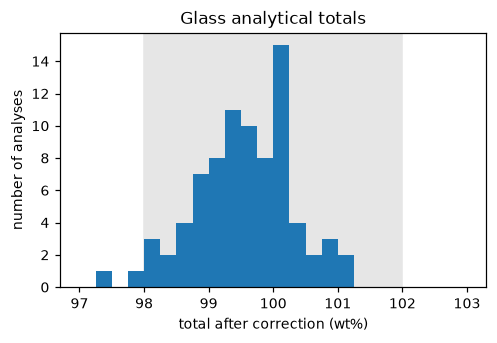

In [8]:
smp = corr[~is_std].copy()
smp["total_flag"] = np.select([smp.Total < 98, smp.Total > 102], ["< 98", "> 102"], "")
print(smp.total_flag.replace("", "98-102").value_counts().to_string())
print(smp.loc[smp.total_flag != "", ["No.", "Comment", "Total"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(smp.Total, bins=np.arange(97, 103.01, 0.25))
ax.axvspan(98, 102, color="0.9", zorder=0)
ax.set(xlabel="total after correction (wt%)", ylabel="number of analyses", title="Glass analytical totals")
fig.savefig(FIG / "totals.png"); plt.show()

Visual check of the sample analyses, oxide by oxide against analysis number (values below are raw). Two analyses are obviously not glass of their sample and are excluded from the figures and averages:
- **No. 49** (`UnknA-C22-PS1-L3_5`): MgO 13.8, CaO 23.3, Al₂O₃ 6.4, Na₂O 0.4 wt%, against 5.4 to 5.8, 11.0 to 12.7, 15.2 to 15.7 and 3.0 to 4.0 in the other eight spots.
- **No. 65** (`UnknA-BatokeCS1-3_4`): Na₂O 8.6 and K₂O 1.3 wt%, against 4.9 to 6.9 and 2.0 to 2.7, with the highest raw total of the session (102.5 wt%).

Two analyses are wrong in one oxide only; that oxide is excluded, the rest of the analysis is kept:
- **No. 32** (`UnknA-C21_6`): SO₃ 2.2 wt% against 0.08 to 0.13 in the other eight spots.
- **No. 70** (`UnknA-BatokeCS1-3_9`): Cl 0.70 wt% against 0.02 to 0.22.

Kept but noted: in `1982-CS2-L3A` spots 7 to 9 (No. 15 to 17) have Na₂O of 4.1 to 4.8 wt% against 2.4 to 2.9 in spots 1 to 6, and `UnknA-BatokeCS1-3` is heterogeneous in several oxides. Neither is obviously wrong; both show up as large 2SD.

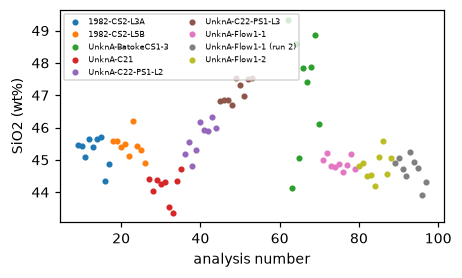

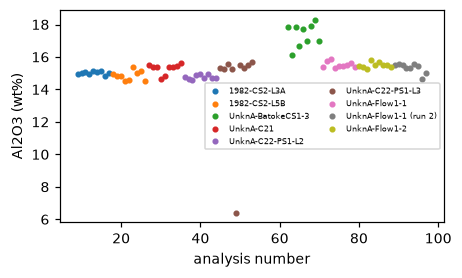

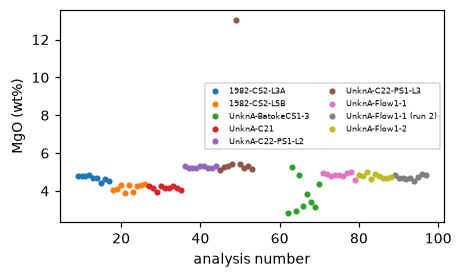

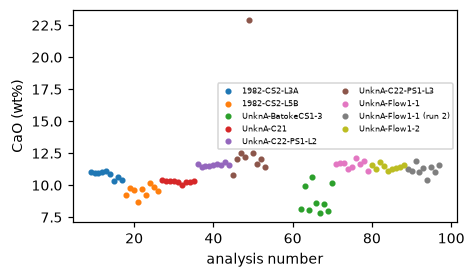

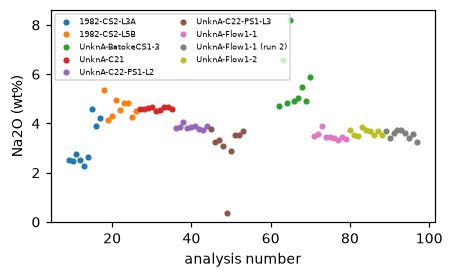

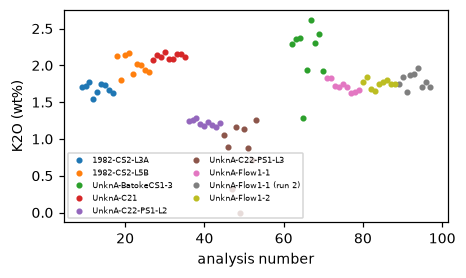

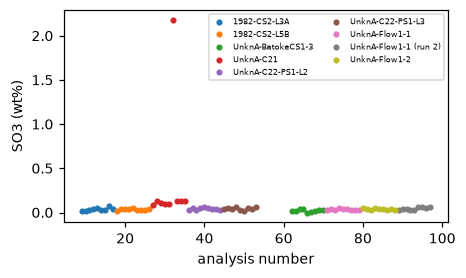

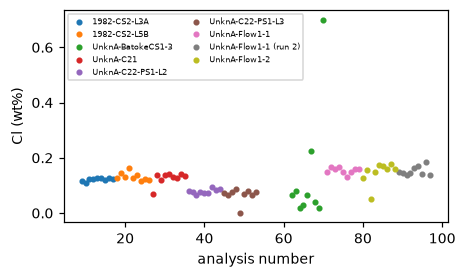

In [9]:
for el in ["SiO2", "Al2O3", "MgO", "CaO", "Na2O", "K2O", "SO3", "Cl"]:
    fig, ax = plt.subplots(figsize=(4.5, 2.5))
    for i, (s, d) in enumerate(smp.groupby("Sample")):
        ax.plot(d["No."], d[el], "o", ms=3, color=f"C{i % 10}", label=s)
    ax.set(xlabel="analysis number", ylabel=f"{el} (wt%)"); ax.legend(fontsize=5, ncol=2)
    plt.show()

BAD = {49: "not glass (MgO 13.8, CaO 23.3 wt%)", 65: "Na2O 8.6 wt%, raw total 102.5 wt%"}   # whole analysis
BAD_EL = {(32, "SO3"): "SO3 2.2 wt%, other spots 0.08 to 0.13", (70, "Cl"): "Cl 0.70 wt%, other spots 0.02 to 0.22"}   # one oxide
smp["exclude"] = smp["No."].isin(BAD)
smp["note"] = smp["No."].map(BAD).fillna("")
for (no, el), why in BAD_EL.items():
    smp.loc[smp["No."].eq(no), "note"] = f"{el} excluded: {why}"          # oxide-level exclusion, applied in step 10

In [10]:
a = smp.loc[smp.Sample.str.startswith("UnknA-Flow1-1"), :].groupby("Sample")[OX]
print("Flow1-1, run 1 vs run 2 (mean ± 2SD):")
print(pd.concat([a.mean().T, 2 * a.std().T], axis=1, keys=["mean", "2SD"]).round(2).to_string())

below = smp[OX].lt(dl.loc[smp["No."]].values)
smp[[f"{el}_bdl" for el in OX]] = below.values
dlt = pd.DataFrame({"DL_median": dl.loc[smp["No."]].median(), "sample_median": smp[OX].median(),
                    "n_below_DL": below.sum(), "n": len(smp)})
print("\ndetection limits, wt% oxide:"); print(dlt.round(4).to_string())

Flow1-1, run 1 vs run 2 (mean ± 2SD):
                mean                                 2SD                      
Sample UnknA-Flow1-1 UnknA-Flow1-1 (run 2) UnknA-Flow1-1 UnknA-Flow1-1 (run 2)
SiO2           44.90                 44.70          0.39                  0.80
TiO2            3.33                  3.30          0.09                  0.07
Al2O3          15.53                 15.31          0.37                  0.61
FeO            13.22                 13.37          0.82                  1.04
MnO             0.22                  0.25          0.07                  0.11
MgO             4.85                  4.73          0.26                  0.25
CaO            11.62                 11.23          0.60                  0.82
Na2O            3.49                  3.55          0.35                  0.34
K2O             1.72                  1.79          0.15                  0.21
P2O5            0.76                  0.77          0.11                  0.11
SO3           

## Step 10. Final data

Corrected sample analyses with their flags, and sample averages (n, mean, 2SD) of the analyses not excluded (n counts analyses; for C21 SO₃ and BatokeCS1-3 Cl one fewer value enters the mean). Ready for the figures and the paper table.

In [11]:
fin = smp[~smp.exclude].copy()
for (no, el) in BAD_EL:
    fin.loc[fin["No."].eq(no), el] = np.nan
samples = mean_2sd(fin, "Sample", OX + ["Total"])
with pd.ExcelWriter(OUT / "glass_final.xlsx") as xw:
    smp.to_excel(xw, sheet_name="samples corrected", index=False)
    samples.to_excel(xw, sheet_name="sample means")
    qc.to_excel(xw, sheet_name="standard QC")
    acc.to_excel(xw, sheet_name="hold-out accuracy")
    dlt.to_excel(xw, sheet_name="detection limits")
    sc.assign(Sample=STD).reset_index().to_excel(xw, sheet_name="standards corrected", index=False)
    GT.to_frame(STD).T.to_excel(xw, sheet_name="references")
print(len(fin), "analyses,", len(samples), "sample sets")
print(samples.round(2).to_string())

79 analyses, 9 sample sets
                       n   SiO2  SiO2_2SD  TiO2  TiO2_2SD  Al2O3  Al2O3_2SD    FeO  FeO_2SD   MnO  MnO_2SD   MgO  MgO_2SD    CaO  CaO_2SD  Na2O  Na2O_2SD   K2O  K2O_2SD  P2O5  P2O5_2SD   SO3  SO3_2SD    Cl  Cl_2SD     F  F_2SD   Total  Total_2SD
Sample                                                                                                                                                                                                                                               
1982-CS2-L3A           9  45.29      0.90  3.92      0.10  15.02       0.18  13.42     0.84  0.22     0.07  4.68     0.29  10.83     0.59  3.10      1.77  1.68     0.15  0.71      0.12  0.04     0.04  0.12    0.01  0.09   0.04   99.12       0.60
1982-CS2-L5B           9  45.45      0.72  3.81      0.14  14.87       0.59  13.78     1.71  0.26     0.07  4.19     0.36   9.55     0.88  4.63      0.78  2.00     0.26  0.78      0.05  0.04     0.02  0.13    0.03  0.13   0.05   99.61 